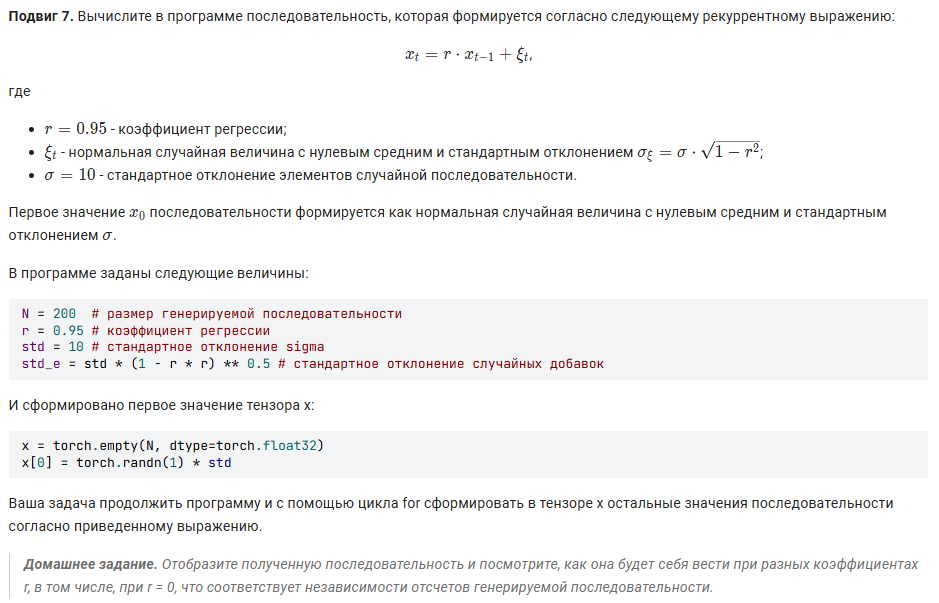

In [21]:
import torch
import torch.nn as nn

N = 200  # размер генерируемой последовательности
r = 0.95 # коэффициент регрессии
std = 10 # стандартное отклонение sigma
std_e = std * (1 - r * r) ** 0.5 # стандартное отклонение случайных добавок

x = torch.empty(N, dtype=torch.float32)
x[0] = torch.randn(1) * std

# здесь продолжайте программу
def func(x):
    return r*x + torch.randn(1)*std_e

for i in range(1, N):
    x[i] = func(x[i-1])

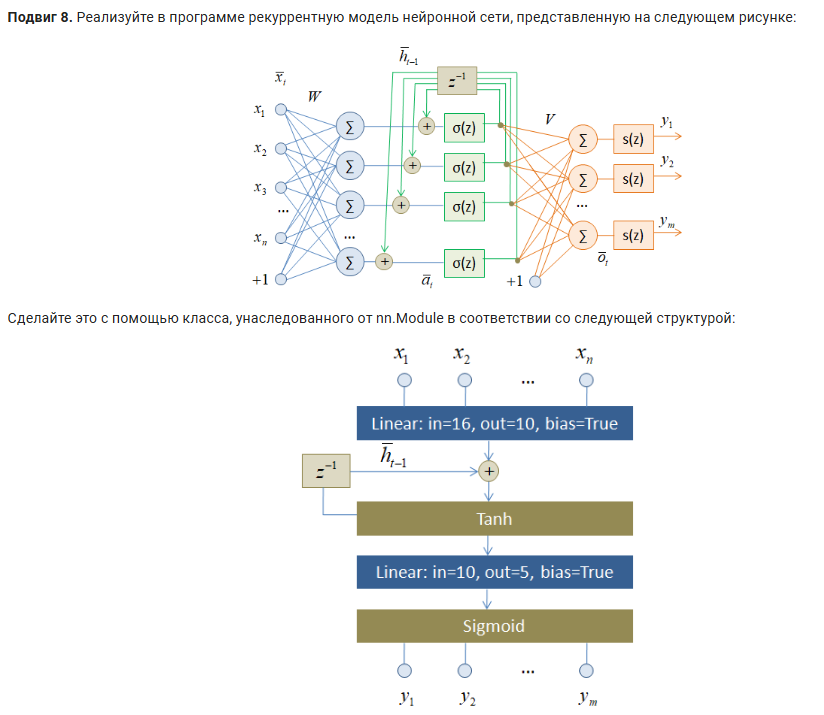
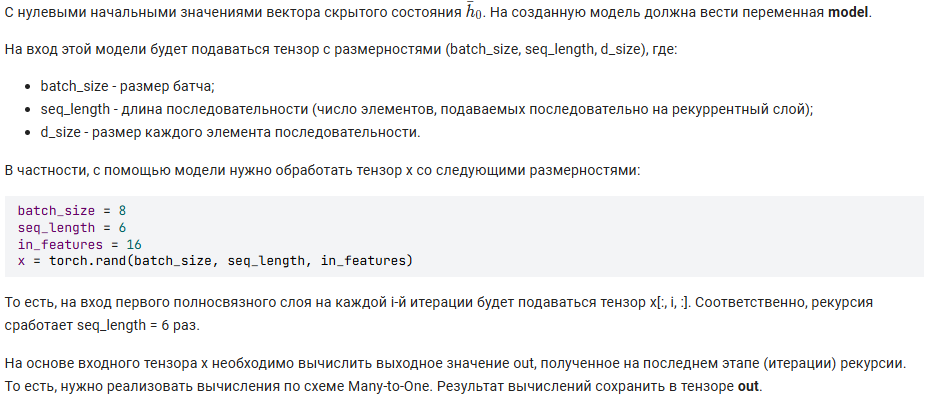

In [35]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class MyRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.h = torch.tensor(10*[0], dtype=torch.float32)
        self.first_ll = nn.Linear(16, 10, bias=True)
        self.tanh = nn.Tanh()
        self.second_ll = nn.Linear(10, 5, bias=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.first_ll(x)
        x += self.h
        self.h = self.tanh(x)
        out = self.second_ll(self.h)
        out = self.sigmoid(out)
        return out

batch_size = 8 # размер батча
seq_length = 6 # длина последовательности
in_features = 16 # размер каждого элемента последовательности
x = torch.rand(batch_size, seq_length, in_features)

# здесь объявляйте саму модель и продолжайте программу
model = MyRNN()
model.eval()

for i in range(6):
    out = model(x[:, i, :])
    
out.shape

torch.Size([8, 5])